<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/06_dependencia_e_gastos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/06_dependencia_e_gastos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resultado final, notebook 06: o dinheiro a mais faz diferença?

Comparamos cada **cidade em destaque** com a sua **cidade gêmea** (notebook 05: mesma mesorregião, população parecida,
mas recebendo o valor normal do RN) para responder três perguntas:

1. **Dependência:** de onde vem a receita da prefeitura? A cidade que recebe mais depende menos de transferências?
2. **Gastos:** para onde vai o dinheiro a mais?
3. **Resultados:** o dinheiro a mais aparece em renda, saneamento, educação e saúde?

No fim, conferimos com os **167 municípios** se o que aparece nos pares vale para o RN inteiro.

## Resumo dos achados

1. **Dependência:** as cidades em destaque continuam **muito dependentes de transferências**: 89% da receita delas vem
   de fora (mediana), só um pouco menos que nas gêmeas (95%). O que muda é **de quem** elas dependem: o Estado (ICMS) pesa de 28% a
   64% da receita das destaques, contra 7% a 13% nas gêmeas, que dependem mais do FPM. Elas têm de 1,4 a 4,9 vezes mais
   receita por habitante.
2. **Gastos:** de cada R\$ 100 que a destaque gasta a mais que a gêmea, a maior fatia vai para **administração e
   Câmara** (mediana de R\$ 40), seguida de **saúde** (R\$ 24) e **educação** (R\$ 20). **Obras urbanas e saneamento
   quase não recebem** a diferença. Pelo tipo de despesa, o gasto a mais vai para **custeio e pessoal**: a parte de
   investimento no gasto das destaques não é maior que nas gêmeas (só é claramente maior em São Bento do Norte e na
   Serra do Mel).
3. **Resultados:** **não há vantagem clara.** Comparando os 7 pares em 7 indicadores, a destaque está melhor em 21
   comparações e a gêmea em 25; na melhora ao longo do tempo, 12 a 11. Os sinais mais favoráveis às destaques são a
   pobreza do Censo (menor em 4 pares e caiu mais em 5), o IDEB (maior em 4 dos 5 pares com dado) e o lixo coletado
   (5 de 7). Na água da rede e no CadÚnico, as gêmeas estão melhor em 6 dos 7 pares; o esgoto fica dividido.
4. **Nos 167 municípios:** quem recebe mais por habitante tem **menos pobreza** (correlação de +0,35, e +0,46 sem o
   efeito do tamanho) e um IDEB um pouco maior (+0,16). Não aparece relação com água, esgoto ou mortalidade infantil.
   A pobreza menor não prova que o dinheiro reduziu a pobreza: a mesma atividade econômica que gera o ICMS também gera
   emprego e renda.

**Em uma frase:** as cidades em destaque recebem e gastam várias vezes mais por habitante, mas esse dinheiro vai
principalmente para a máquina pública (administração, pessoal e custeio), e os indicadores sociais delas não são
claramente melhores que os das gêmeas.

## 1. Bibliotecas e bases

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap
import seaborn as sns
from scipy import stats

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
ANOS = [2020, 2021, 2022, 2023]
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')
pd.set_option('display.max_colwidth', 60)

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
ROXO, VERMELHO, CINZA, CINZA_CLARO = '#7d55c7', '#d0453c', '#a3a29b', '#d6d5d0'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    """Formata em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000 -> 'R$ 2,3 mi'."""
    sinal = '−' if x < 0 else ''
    x = abs(x)
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if x >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'{sinal}R$ {texto}{sufixo}'
    return f'{sinal}R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, tentativas=3, **kwargs):
    """Lê do GitHub do projeto (tenta de novo se a conexão cair); se não conseguir, lê a cópia local (mesmo caminho)."""
    for _ in range(tentativas):
        try:
            return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
        except Exception as e:
            erro = e
            if '404' in str(e):
                break
            time.sleep(3)
    if os.path.exists(caminho):
        return pd.read_csv(caminho, **kwargs)
    if '404' in str(erro):
        raise FileNotFoundError(
            f'O arquivo "{caminho}" não está no GitHub do projeto. '
            f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
            'e rode a célula de novo.') from None
    raise ConnectionError(
        f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
        f'Erro original: {erro}') from None

pares = ler_csv('resultado_final/saida/05_pares_gemeos.csv')
uni = ler_csv('resultado_final/saida/04_base_unificada_2020_2023.csv')
base01 = ler_csv('resultado_final/saida/01_base_municipios_2020_2023.csv')
FATOR_IPCA = base01.drop_duplicates('ano').set_index('ano')['fator_ipca']
POP = uni.set_index('cod_ibge')['populacao']
NOME = uni.set_index('cod_ibge')['municipio']

PARES = list(zip(pares['destaque'], pares['gemea']))
DESTAQUES = pares['destaque'].tolist()
GEMEAS = pares['gemea'].tolist()
CIDADES = DESTAQUES + GEMEAS
ROTULO_PAR = {d: f'{d} × {g}' + (' (fronteira)' if f else '')
              for d, g, f in zip(pares['destaque'], pares['gemea'], pares['fronteira'])}
pares[['destaque', 'gemea', 'mesorregiao', 'dif_populacao_pct', 'vezes_mais_dinheiro']]

,destaque,gemea,mesorregiao,dif_populacao_pct,vezes_mais_dinheiro
0,Guamaré,Jardim de Piranhas,Central Potiguar,-8.6,20.3
1,Galinhos,Fernando Pedroza,Central Potiguar,39.6,5.0
2,Parazinho,Bento Fernandes,Agreste Potiguar,0.1,6.8
3,São Bento do Norte,São Fernando,Central Potiguar,5.7,4.2
4,Pedra Grande,Senador Georgino Avelino,Leste Potiguar,12.4,6.5
5,Bodó,Caiçara do Rio do Vento,Central Potiguar,41.7,4.3
6,Serra do Mel,Alexandria,Oeste Potiguar,4.2,4.4


**Dados do SICONFI.** As receitas e despesas de cada prefeitura vêm da Declaração de Contas Anuais (DCA) do Tesouro
Nacional: anexo I-C (receitas), I-D (despesas por tipo) e I-E (despesas por área). O arquivo
`dados/siconfi/dca_pares_2020_2023.csv` tem as 14 cidades dos pares, de 2020 a 2023. Para baixar de novo pela API do
Tesouro, mude `BAIXAR_SICONFI` para `True` (leva cerca de 2 minutos).

In [2]:
BAIXAR_SICONFI = False

def baixar_siconfi(codigos, anos):
    import requests
    linhas = []
    for ano in anos:
        for anexo in ['DCA-Anexo I-C', 'DCA-Anexo I-D', 'DCA-Anexo I-E']:
            for cod in codigos:
                r = requests.get('https://apidatalake.tesouro.gov.br/ords/siconfi/tt/dca',
                                 params={'an_exercicio': ano, 'no_anexo': anexo, 'id_ente': cod}, timeout=90)
                linhas += r.json()['items']
                time.sleep(0.3)
    return pd.DataFrame(linhas)[['exercicio', 'cod_ibge', 'instituicao', 'anexo', 'coluna', 'cod_conta', 'conta', 'valor']]

codigos = sorted(set(pares['cod_ibge_destaque']) | set(pares['cod_ibge_gemea']))
dca = baixar_siconfi(codigos, ANOS) if BAIXAR_SICONFI else ler_csv('dados/siconfi/dca_pares_2020_2023.csv')
assert dca.groupby(['exercicio', 'anexo'])['cod_ibge'].nunique().eq(14).all(), 'falta cidade ou ano no SICONFI'
dca['municipio'] = dca['cod_ibge'].map(NOME)
dca['valor_real'] = dca['valor'] * dca['exercicio'].map(FATOR_IPCA)
dca['valor_pc'] = dca['valor_real'] / dca['cod_ibge'].map(POP)
print(f'{len(dca):,} linhas do SICONFI | 14 cidades × 4 anos × 3 anexos'.replace(',', '.'))

21.130 linhas do SICONFI | 14 cidades × 4 anos × 3 anexos


## 2. Dependência: de onde vem a receita da prefeitura?

Dividimos a **receita corrente** (o dinheiro do dia a dia da prefeitura, sem empréstimos nem venda de bens) em seis
partes:

| Parte | O que é |
|---|---|
| Transferências do Estado | Principalmente a cota-parte do ICMS e do IPVA (os repasses do notebook 01) |
| FPM | Fundo de Participação dos Municípios, da União |
| Outras transferências da União | SUS, FNDE (merenda, transporte escolar), assistência social, royalties |
| FUNDEB | Fundo da educação básica |
| Outras transferências | Convênios correntes, outras origens |
| Receita própria | Impostos municipais (IPTU, ISS, ITBI), taxas e outras receitas da própria prefeitura |

**Atenção ao código do FPM:** o plano de contas mudou em 2022. Em 2020 e 2021 o FPM está dentro de "Participação na
Receita da União" (tirando a cota do ITR); a partir de 2022 tem conta própria.

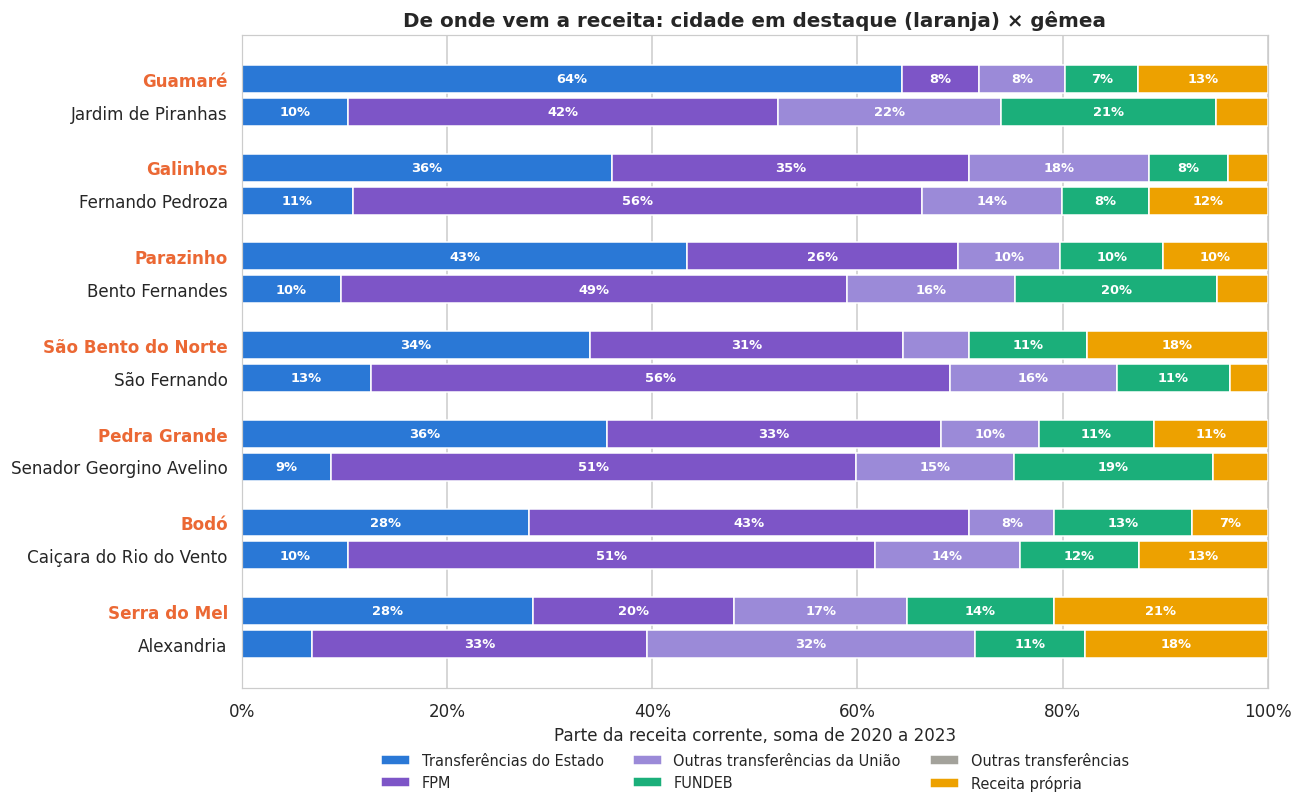

,Transferências (% da receita),Só do Estado (%),Receita própria (%),Receita corrente (R$/hab/ano)
municipio,,,,
Guamaré,87.4,64.3,12.6,"19,876.5"
Galinhos,96.1,36.0,3.9,"19,372.0"
Parazinho,89.8,43.4,10.2,"11,172.9"
São Bento do Norte,82.3,33.9,17.7,"14,061.1"
Pedra Grande,88.9,35.6,11.1,"12,033.7"
Bodó,92.6,28.0,7.4,"14,335.1"
Serra do Mel,79.2,28.4,20.8,"7,362.6"
Jardim de Piranhas,94.9,10.3,5.1,"4,064.2"
Fernando Pedroza,88.4,10.8,11.6,"8,760.4"


In [3]:
rec = dca[(dca['anexo'] == 'DCA-Anexo I-C') & (dca['coluna'] == 'Receitas Brutas Realizadas')]
r = rec.pivot_table(index=['cod_ibge', 'exercicio'], columns='cod_conta', values='valor_real', aggfunc='sum').fillna(0)
fpm = np.where(r.index.get_level_values('exercicio') >= 2022, r.get('RO1.7.1.1.51.0.0', 0),
               r.get('RO1.7.1.8.01.0.0', 0) - r.get('RO1.7.1.8.01.5.0', 0))
receita = pd.DataFrame({
    'Transferências do Estado': r['RO1.7.2.0.00.0.0'],
    'FPM': fpm,
    'Outras transferências da União': r['RO1.7.1.0.00.0.0'] - fpm,
    'FUNDEB': r.get('RO1.7.5.0.00.0.0', 0),
}, index=r.index)
receita['Outras transferências'] = r['RO1.7.0.0.00.0.0'] - receita.sum(axis=1)
receita['Receita própria'] = r['RO1.0.0.0.00.0.0'] - r['RO1.7.0.0.00.0.0']
receita['total'] = r['RO1.0.0.0.00.0.0']
assert np.allclose(receita.drop(columns='total').sum(axis=1), receita['total'])
PARTES_RECEITA = [('Transferências do Estado', AZUL), ('FPM', ROXO), ('Outras transferências da União', '#9b8ad8'),
                  ('FUNDEB', VERDE), ('Outras transferências', CINZA), ('Receita própria', AMARELO)]
receita = receita.reset_index()
receita['municipio'] = receita['cod_ibge'].map(NOME)

media_rec = receita.groupby('municipio')[[p for p, _ in PARTES_RECEITA] + ['total']].sum()
fatias = media_rec[[p for p, _ in PARTES_RECEITA]].div(media_rec['total'], axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 7.5))
y_pos, rotulos = [], []
for i, (d, g) in enumerate(PARES):
    for j, nome in enumerate([d, g]):
        pos = i * 2.7 + j
        y_pos.append(pos)
        rotulos.append(nome)
        esquerda = 0
        for parte, cor in PARTES_RECEITA:
            v = fatias.loc[nome, parte]
            ax.barh(pos, v, left=esquerda, color=cor, height=0.85, edgecolor='white', linewidth=1,
                    label=parte if (i == 0 and j == 0) else None)
            if v >= 7:
                ax.text(esquerda + v / 2, pos, f'{v:.0f}%', ha='center', va='center', fontsize=8.5, color='white',
                        fontweight='bold')
            esquerda += v
ax.set_yticks(y_pos)
ax.set_yticklabels(rotulos)
for rot in ax.get_yticklabels():
    if rot.get_text() in DESTAQUES:
        rot.set_fontweight('bold')
        rot.set_color(LARANJA)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel('Parte da receita corrente, soma de 2020 a 2023')
ax.set_title('De onde vem a receita: cidade em destaque (laranja) × gêmea')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False, fontsize=9.5)
plt.tight_layout()
plt.show()

dependencia = pd.DataFrame({
    'Transferências (% da receita)': 100 - fatias['Receita própria'],
    'Só do Estado (%)': fatias['Transferências do Estado'],
    'Receita própria (%)': fatias['Receita própria'],
    'Receita corrente (R$/hab/ano)': media_rec['total'] / media_rec.index.map(uni.set_index('municipio')['populacao']) / 4,
}).loc[CIDADES]
dependencia.round(1)

### 2.1 Ano a ano

A receita corrente por habitante de cada par, em cada ano, e a parte que vem de receita própria.

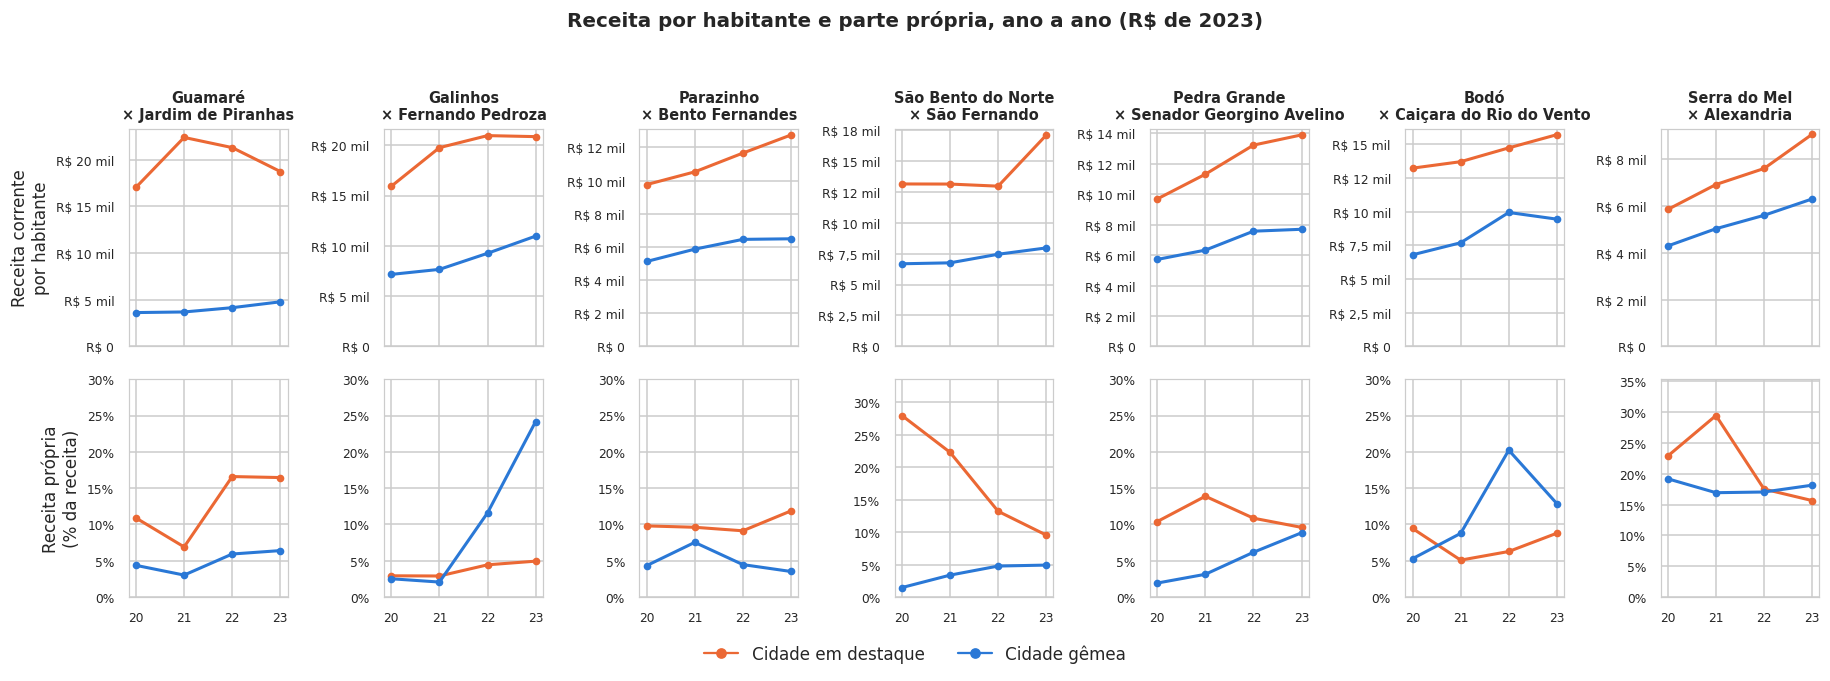

In [4]:
receita['pc'] = receita['total'] / receita['cod_ibge'].map(POP)
receita['pct_propria'] = receita['Receita própria'] / receita['total'] * 100
fig, axes = plt.subplots(2, len(PARES), figsize=(2.4 * len(PARES), 6.2), sharex=True)
for k, (d, g) in enumerate(PARES):
    for linha_ax, (col, fmt) in enumerate([('pc', FORMATO_REAIS), ('pct_propria', mticker.PercentFormatter(decimals=0))]):
        ax = axes[linha_ax, k]
        for nome, cor in [(d, LARANJA), (g, AZUL)]:
            t = receita[receita['municipio'] == nome].sort_values('exercicio')
            ax.plot(t['exercicio'], t[col], color=cor, marker='o', linewidth=2, markersize=4, label=nome)
        ax.yaxis.set_major_formatter(fmt)
        ax.tick_params(labelsize=8)
        ax.set_xticks(ANOS)
        ax.set_xticklabels(['20', '21', '22', '23'])
        if linha_ax == 0:
            ax.set_title(f'{d}\n× {g}', fontsize=9.5)
            ax.set_ylim(0, None)
        else:
            ax.set_ylim(0, max(30, receita.loc[receita['municipio'].isin([d, g]), col].max() * 1.2))
axes[0, 0].set_ylabel('Receita corrente\npor habitante')
axes[1, 0].set_ylabel('Receita própria\n(% da receita)')
fig.legend([plt.Line2D([], [], color=LARANJA, marker='o'), plt.Line2D([], [], color=AZUL, marker='o')],
           ['Cidade em destaque', 'Cidade gêmea'], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0))
fig.suptitle('Receita por habitante e parte própria, ano a ano (R$ de 2023)', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.show()

## 3. Gastos: para onde vai o dinheiro a mais?

**O que é "o dinheiro a mais":** é a diferença por habitante entre a destaque e a gêmea. Exemplo: Parazinho recebe
cerca de R\$ 5.300 por habitante por ano, e sua gêmea, Bento Fernandes, cerca de R\$ 800. A diferença, uns R\$ 4.500
por habitante por ano, é "o dinheiro a mais".

**Esse valor não dá para rastrear sozinho.** O ICMS e a maior parte das transferências caem no mesmo caixa da
prefeitura e não chegam "carimbados": não existe um registro dizendo "este real veio da usina e foi gasto em tal
coisa". Por isso olhamos **o orçamento inteiro** de cada cidade e comparamos com o da gêmea. Como as duas têm o mesmo
tamanho e ficam na mesma região, **a diferença de gasto entre elas é a melhor aproximação de onde foi parar o dinheiro
a mais.**

Os gráficos desta seção respondem: **de cada R\$ 100 que Parazinho gasta a mais que a gêmea, quanto vai para educação,
saúde, obras...**

Usamos a **despesa liquidada** (o serviço ou a obra foi entregue e a prefeitura reconheceu a dívida), por habitante,
em R\$ de 2023.

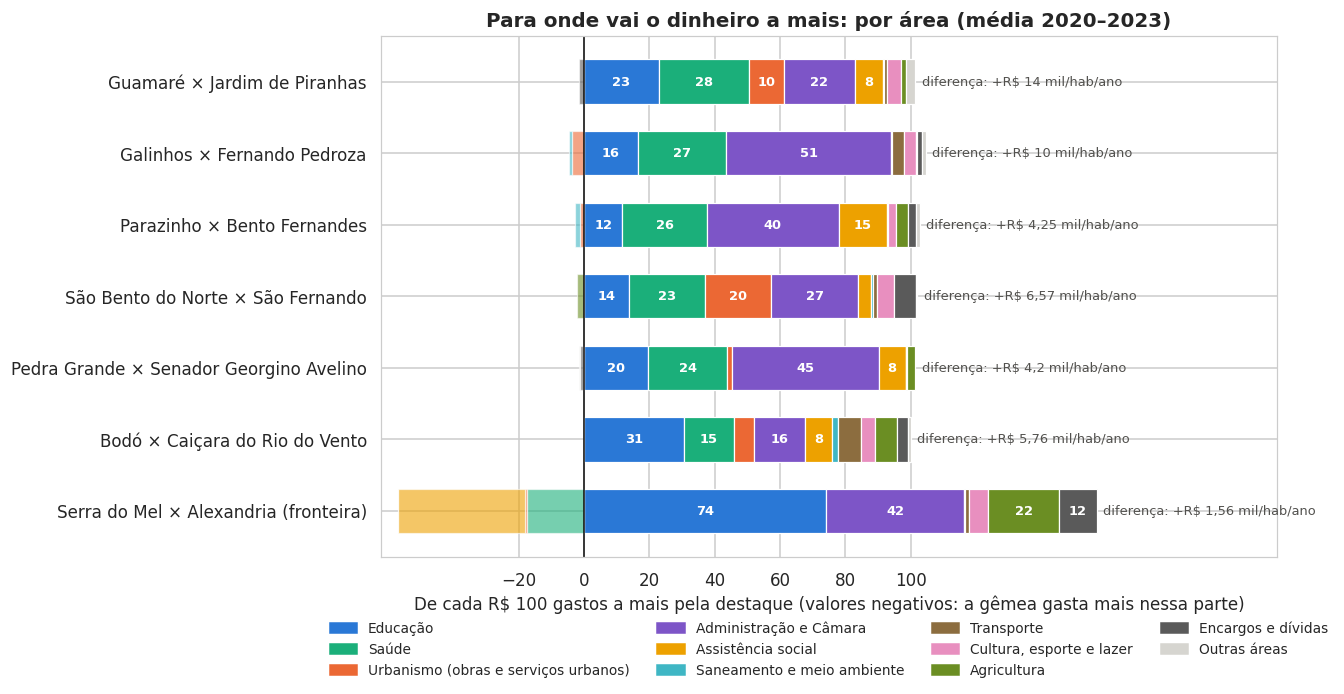

area,Gasta a mais (R$/hab/ano),Educação,Saúde,Urbanismo (obras e serviços urbanos),Administração e Câmara,Assistência social,Saneamento e meio ambiente,Transporte,"Cultura, esporte e lazer",Agricultura,Encargos e dívidas,Outras áreas
Guamaré,"13,619.0",23.0,28.0,10.0,22.0,8.0,0.0,1.0,4.0,2.0,-1.0,3.0
Galinhos,"10,220.0",16.0,27.0,-4.0,51.0,0.0,-1.0,4.0,4.0,0.0,2.0,1.0
Parazinho,"4,246.0",12.0,26.0,-1.0,40.0,15.0,-1.0,0.0,2.0,4.0,3.0,1.0
São Bento do Norte,"6,567.0",14.0,23.0,20.0,27.0,4.0,1.0,1.0,5.0,-2.0,7.0,0.0
Pedra Grande,"4,195.0",20.0,24.0,2.0,45.0,8.0,0.0,0.0,-0.0,2.0,-1.0,-0.0
Bodó,"5,764.0",31.0,15.0,6.0,16.0,8.0,2.0,7.0,4.0,7.0,3.0,1.0
Serra do Mel,"1,564.0",74.0,-17.0,-1.0,42.0,-39.0,0.0,1.0,6.0,22.0,12.0,-0.0


In [5]:
desp_area = dca[(dca['anexo'] == 'DCA-Anexo I-E') & (dca['coluna'] == 'Despesas Liquidadas')].copy()
# As linhas depois de "Despesas Intraorçamentárias" repetem as áreas para operações internas da prefeitura: ficam fora
desp_area['intra'] = (desp_area['conta'].eq('Despesas Intraorçamentárias')
                      .groupby([desp_area['cod_ibge'], desp_area['exercicio']]).cumsum() > 0)
desp_area = desp_area[~desp_area['intra']]
funcoes = desp_area[desp_area['conta'].str.match(r'^\d{2} - ')].copy()
funcoes['codigo'] = funcoes['conta'].str[:2]
total_desp = desp_area[desp_area['conta'] == 'Despesas Exceto Intraorçamentárias'].set_index(['cod_ibge', 'exercicio'])['valor']
soma_funcoes = funcoes.groupby(['cod_ibge', 'exercicio'])['valor'].sum()
assert np.allclose(soma_funcoes, total_desp.reindex(soma_funcoes.index), rtol=1e-3), 'áreas não somam o total'

AREAS = {'12': 'Educação', '10': 'Saúde', '15': 'Urbanismo (obras e serviços urbanos)',
         '04': 'Administração e Câmara', '01': 'Administração e Câmara', '08': 'Assistência social',
         '17': 'Saneamento e meio ambiente', '18': 'Saneamento e meio ambiente', '26': 'Transporte',
         '13': 'Cultura, esporte e lazer', '27': 'Cultura, esporte e lazer', '23': 'Cultura, esporte e lazer',
         '20': 'Agricultura', '09': 'Previdência', '28': 'Encargos e dívidas'}
funcoes['area'] = funcoes['codigo'].map(AREAS).fillna('Outras áreas')
CORES_AREA = {'Educação': AZUL, 'Saúde': VERDE, 'Urbanismo (obras e serviços urbanos)': LARANJA,
              'Administração e Câmara': ROXO, 'Assistência social': AMARELO, 'Saneamento e meio ambiente': '#3fb6c4',
              'Transporte': '#8c6d3f', 'Cultura, esporte e lazer': '#e88fbf', 'Agricultura': '#6b8e23',
              'Previdência': '#9e9e9e', 'Encargos e dívidas': '#5a5a5a', 'Outras áreas': CINZA_CLARO}

area_pc = (funcoes.groupby(['municipio', 'area'])['valor_real'].sum().unstack(fill_value=0)
           .div(uni.set_index('municipio')['populacao'], axis=0).dropna() / 4)
area_pc = area_pc[[a for a in CORES_AREA if a in area_pc]]

def decompor_diferenca(tabela):
    """Para cada par: diferença por área (destaque − gêmea) e quanto ela representa de cada R$ 100 da diferença total."""
    linhas = []
    for d, g in PARES:
        dif = tabela.loc[d] - tabela.loc[g]
        total = dif.sum()
        linhas.append(pd.Series(dif / total * 100, name=d).rename(lambda a: a))
        linhas[-1]['__total'] = total
    return pd.DataFrame(linhas)

dec_area = decompor_diferenca(area_pc)

def grafico_decomposicao(dec, cores, titulo):
    fig, ax = plt.subplots(figsize=(12, 6.5))
    y = np.arange(len(dec))[::-1]
    for yi, (destaque, linha) in zip(y, dec.iterrows()):
        pos, neg = 0, 0
        for parte, cor in cores.items():
            v = linha.get(parte, 0)
            if v >= 0:
                ax.barh(yi, v, left=pos, color=cor, height=0.62, edgecolor='white', linewidth=0.8)
                if v >= 7:
                    ax.text(pos + v / 2, yi, f'{v:.0f}', ha='center', va='center', fontsize=8.5, color='white',
                            fontweight='bold')
                pos += v
            else:
                ax.barh(yi, v, left=neg, color=cor, height=0.62, edgecolor='white', linewidth=0.8, alpha=0.6)
                neg += v
        ax.text(max(pos, 100) + 2, yi, f'diferença: +{reais(linha["__total"])}/hab/ano', va='center', fontsize=8.5,
                color=TEXTO_2)
    ax.axvline(0, color=TEXTO, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels([ROTULO_PAR[d] for d in dec.index])
    maior = dec.drop(columns='__total').clip(lower=0).sum(axis=1).max()
    ax.set_xlim(min(-25, dec.drop(columns='__total').clip(upper=0).sum(axis=1).min() - 5), max(150, maior + 55))
    ax.xaxis.set_major_locator(mticker.FixedLocator([-20, 0, 20, 40, 60, 80, 100]))
    ax.set_xlabel('De cada R$ 100 gastos a mais pela destaque (valores negativos: a gêmea gasta mais nessa parte)')
    ax.set_title(titulo)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()]
    ax.legend(handles, list(cores), loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

grafico_decomposicao(dec_area, {a: c for a, c in CORES_AREA.items() if a in dec_area},
                     'Para onde vai o dinheiro a mais: por área (média 2020–2023)')

resumo_area = dec_area.drop(columns='__total').round(0)
resumo_area.insert(0, 'Gasta a mais (R$/hab/ano)', dec_area['__total'].round(0))
resumo_area

**Recebe a mais × gasta a mais.** O gasto a mais pode ser **maior** que o dinheiro a mais das quatro fontes do
notebook 04. Isso acontece porque outras receitas também diferem entre as duas cidades: o FPM por habitante é maior nos
municípios menores, e SUS e FNDE variam com o número de atendimentos e alunos. A tabela compara as três medidas.

In [6]:
uni_i = uni.set_index('municipio')
rc_pc = media_rec['total'] / media_rec.index.map(uni_i['populacao']) / 4
pd.DataFrame({
    'Recebe a mais nas 4 fontes do 04': [uni_i.loc[d, 'total_pc_ano'] - uni_i.loc[g, 'total_pc_ano'] for d, g in PARES],
    'Receita corrente a mais (SICONFI)': [rc_pc[d] - rc_pc[g] for d, g in PARES],
    'Gasta a mais (SICONFI)': dec_area['__total'].values,
}, index=[ROTULO_PAR[d] for d, _ in PARES]).round(0)

,Recebe a mais nas 4 fontes do 04,Receita corrente a mais (SICONFI),Gasta a mais (SICONFI)
Guamaré × Jardim de Piranhas,"12,673.0","15,812.0","13,619.0"
Galinhos × Fernando Pedroza,"4,477.0","10,612.0","10,220.0"
Parazinho × Bento Fernandes,"4,484.0","5,189.0","4,246.0"
São Bento do Norte × São Fernando,"3,782.0","6,854.0","6,567.0"
Pedra Grande × Senador Georgino Avelino,"4,176.0","5,205.0","4,195.0"
Bodó × Caiçara do Rio do Vento,"3,234.0","5,872.0","5,764.0"
Serra do Mel × Alexandria (fronteira),"1,733.0","2,054.0","1,564.0"


**Quantas vezes a destaque gasta mais que a gêmea, por área** (gasto por habitante da destaque ÷ da gêmea). Um valor
de 1,0 quer dizer gasto igual por habitante.

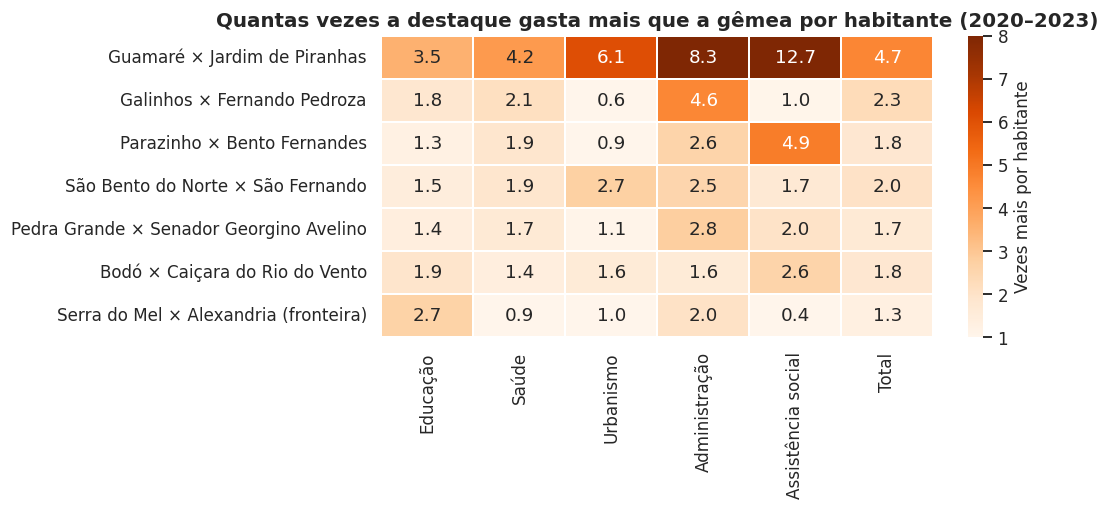

In [7]:
vezes = pd.DataFrame({d: area_pc.loc[d] / area_pc.loc[g] for d, g in PARES}).T
principais = ['Educação', 'Saúde', 'Urbanismo (obras e serviços urbanos)', 'Administração e Câmara', 'Assistência social']
vezes_tab = vezes[principais].copy()
vezes_tab['Total'] = [area_pc.loc[d].sum() / area_pc.loc[g].sum() for d, g in PARES]
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(vezes_tab.rename(index=ROTULO_PAR, columns={'Urbanismo (obras e serviços urbanos)': 'Urbanismo',
                                                         'Administração e Câmara': 'Administração'}),
            annot=True, fmt='.1f', cmap='Oranges', vmin=1, vmax=8, linewidths=1, linecolor='white',
            cbar_kws={'label': 'Vezes mais por habitante'}, ax=ax)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('Quantas vezes a destaque gasta mais que a gêmea por habitante (2020–2023)')
plt.tight_layout()
plt.show()

### 3.1 Pessoal, custeio ou investimento?

A mesma pergunta pelo **tipo** de despesa:

- **Pessoal:** salários, encargos e aposentadorias;
- **Custeio:** material, serviços de terceiros, contratos, auxílios;
- **Investimento:** obras, equipamentos e material permanente.

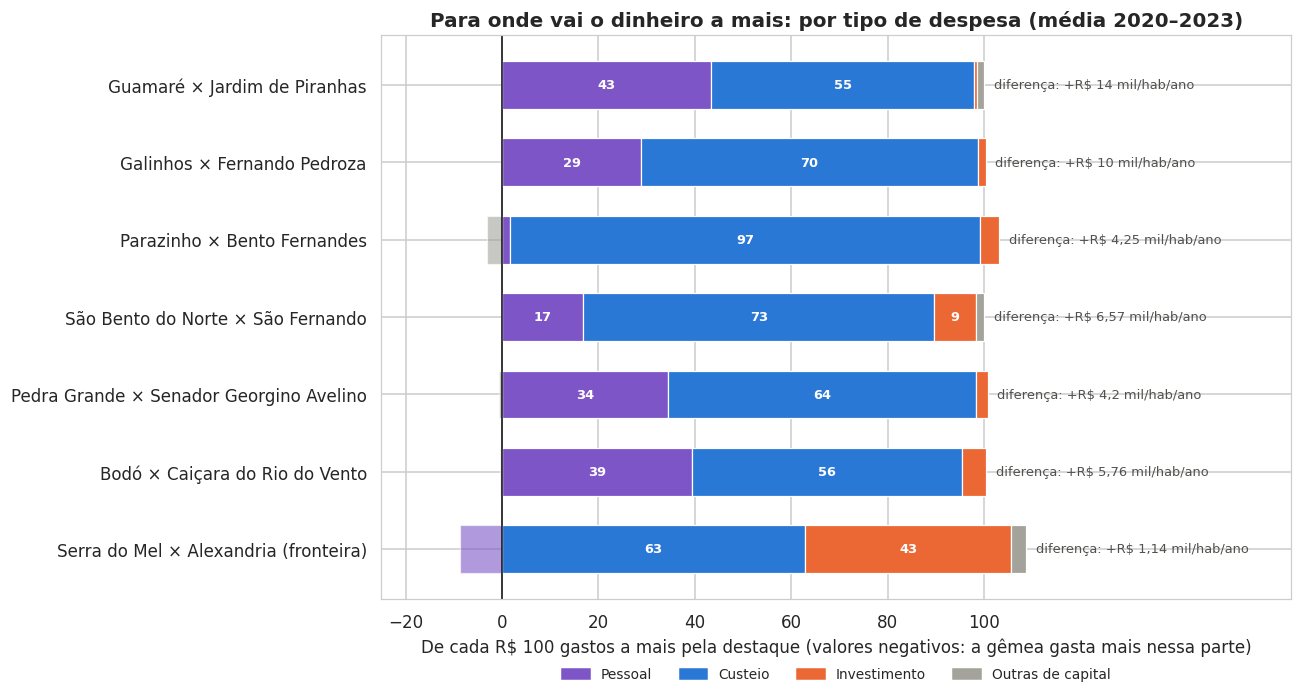

,Investimento: destaque (% do gasto),Investimento: gêmea (% do gasto),Pessoal: destaque (% do gasto),Pessoal: gêmea (% do gasto)
Guamaré × Jardim de Piranhas,1.7,5.8,46.1,55.9
Galinhos × Fernando Pedroza,2.7,4.0,38.0,49.9
Parazinho × Bento Fernandes,5.0,5.8,35.7,63.2
São Bento do Norte × São Fernando,6.9,5.2,34.7,52.9
Pedra Grande × Senador Georgino Avelino,6.4,9.2,46.1,53.9
Bodó × Caiçara do Rio do Vento,4.8,4.5,49.2,57.1
Serra do Mel × Alexandria (fronteira),10.7,3.8,40.4,51.0


In [8]:
desp_tipo = dca[(dca['anexo'] == 'DCA-Anexo I-D') & (dca['coluna'] == 'Despesas Liquidadas')]
t = desp_tipo.pivot_table(index='municipio', columns='cod_conta', values='valor_real', aggfunc='sum').fillna(0)
tipo = pd.DataFrame({
    'Pessoal': t['DO3.1.00.00.00.00'],
    'Custeio': t['DO3.3.00.00.00.00'] + t.get('DO3.2.00.00.00.00', 0),
    'Investimento': t.get('DO4.4.00.00.00.00', 0),
    'Outras de capital': t.get('DO4.0.00.00.00.00', 0) - t.get('DO4.4.00.00.00.00', 0),
})
tipo_pc = tipo.div(uni.set_index('municipio')['populacao'], axis=0).dropna() / 4
CORES_TIPO = {'Pessoal': ROXO, 'Custeio': AZUL, 'Investimento': LARANJA, 'Outras de capital': CINZA}
dec_tipo = decompor_diferenca(tipo_pc)
grafico_decomposicao(dec_tipo, CORES_TIPO, 'Para onde vai o dinheiro a mais: por tipo de despesa (média 2020–2023)')

parte_tipo = tipo_pc.div(tipo_pc.sum(axis=1), axis=0) * 100
comparacao_tipo = pd.DataFrame({
    'Investimento: destaque (% do gasto)': [parte_tipo.loc[d, 'Investimento'] for d, _ in PARES],
    'Investimento: gêmea (% do gasto)': [parte_tipo.loc[g, 'Investimento'] for _, g in PARES],
    'Pessoal: destaque (% do gasto)': [parte_tipo.loc[d, 'Pessoal'] for d, _ in PARES],
    'Pessoal: gêmea (% do gasto)': [parte_tipo.loc[g, 'Pessoal'] for _, g in PARES],
}, index=[ROTULO_PAR[d] for d, _ in PARES])
comparacao_tipo.round(1)

### 3.2 Ano a ano: gasto por habitante em educação, saúde e investimento

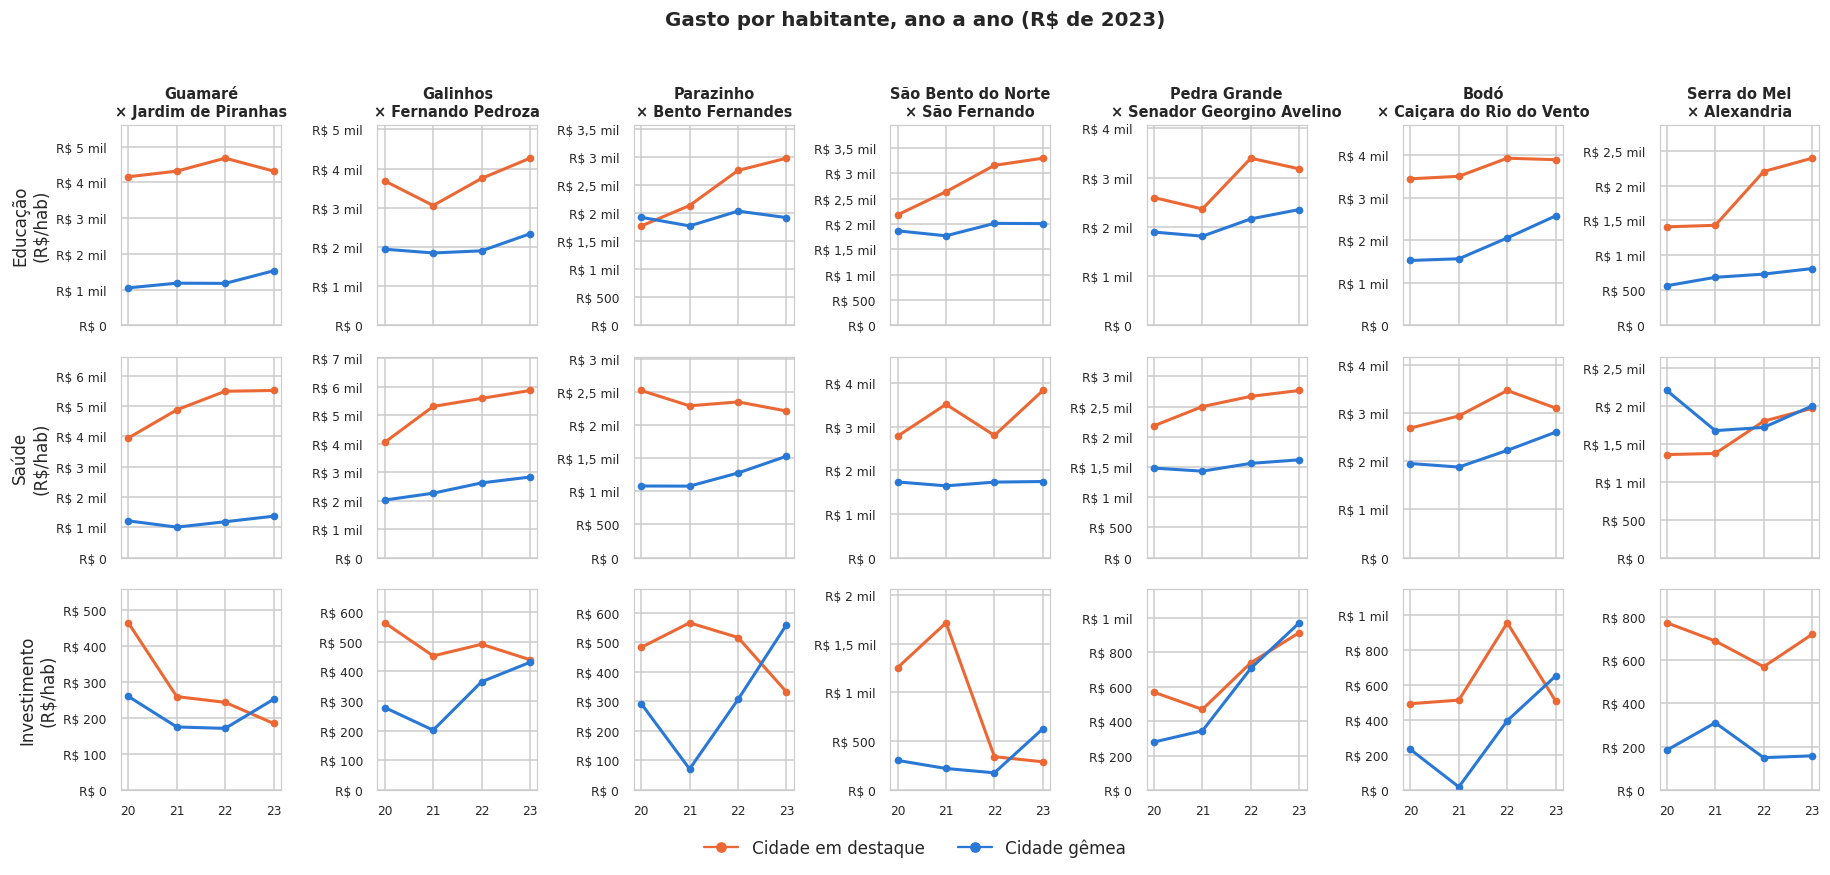

In [9]:
ano_area = funcoes.groupby(['municipio', 'exercicio', 'area'])['valor_pc'].sum().unstack(fill_value=0)
ano_tipo = (desp_tipo[desp_tipo['cod_conta'] == 'DO4.4.00.00.00.00'].groupby(['municipio', 'exercicio'])['valor_pc'].sum()
            .rename('Investimento'))
ano = ano_area[['Educação', 'Saúde']].join(ano_tipo).fillna(0)
fig, axes = plt.subplots(3, len(PARES), figsize=(2.4 * len(PARES), 8), sharex=True)
for k, (d, g) in enumerate(PARES):
    for i, col in enumerate(['Educação', 'Saúde', 'Investimento']):
        ax = axes[i, k]
        for nome, cor in [(d, LARANJA), (g, AZUL)]:
            s = ano.loc[nome, col]
            ax.plot(s.index, s.values, color=cor, marker='o', linewidth=2, markersize=4)
        ax.set_ylim(0, ano.loc[[d, g], col].max() * 1.2)
        ax.yaxis.set_major_formatter(FORMATO_REAIS)
        ax.tick_params(labelsize=8)
        ax.set_xticks(ANOS)
        ax.set_xticklabels(['20', '21', '22', '23'])
        if i == 0:
            ax.set_title(f'{d}\n× {g}', fontsize=9.5)
        if k == 0:
            ax.set_ylabel(f'{col}\n(R$/hab)')
fig.legend([plt.Line2D([], [], color=LARANJA, marker='o'), plt.Line2D([], [], color=AZUL, marker='o')],
           ['Cidade em destaque', 'Cidade gêmea'], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0))
fig.suptitle('Gasto por habitante, ano a ano (R$ de 2023)', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

## 4. Resultados: o dinheiro a mais virou melhoria?

Os indicadores entram como **parâmetros de comparação** (nenhum deles foi usado para escolher os pares):

| Área | Indicador | Nível (como está) | Mudança (quanto melhorou) |
|---|---|---|---|
| Renda | % da população com renda de até ½ salário mínimo (Censo) | 2022 | 2010 → 2022 |
| Renda | Pessoas de baixa renda no CadÚnico (% da população) | média 2020–2023 | 2020 → 2023 |
| Saneamento | Domicílios com água da rede, esgoto adequado e lixo coletado (Censo) | 2022 | (não comparamos, ver abaixo) |
| Educação | IDEB da rede municipal, 1º ao 5º ano (INEP) | 2023 | 2019 → 2023 |
| Saúde | Mortalidade infantil: mortes antes de 1 ano por mil nascidos vivos (DATASUS) | 2020–2023 juntos | 2016–2019 → 2020–2023 |

**Saneamento só pelo nível de 2022:** o IBGE mudou a forma de perguntar sobre água e esgoto entre os Censos de 2010 e
2022 (por exemplo, como classificar fossas). Em vários municípios a "mudança" fica impossível: em Guamaré a água da
rede teria caído de 87% para 38% dos domicílios, e em São Bento do Norte o esgoto adequado, de 66% para 3%. No RN, 34
municípios teriam o esgoto mudando mais de 30 pontos em 12 anos. Por isso não comparamos a mudança no saneamento.

**Mortalidade infantil em cidade pequena:** em Galinhos nascem cerca de 30 crianças por ano, então uma única morte
muda muito a taxa. Por isso somamos quatro anos de cada vez. Mesmo assim, diferenças pequenas nesse indicador não
devem ser levadas a sério nas cidades menores.

In [10]:
censo_ind = ler_csv('dados/ibge/censo2010_2022_indicadores_rn.csv')
censo22 = ler_csv('dados/ibge/censo2022_renda_rn.csv')[['cod_ibge', 'pct_ate_meio_sm_censo']]
ideb = ler_csv('dados/inep/ideb_rede_municipal_rn.csv')[['cod_ibge', 'ai_2017', 'ai_2019', 'ai_2021', 'ai_2023']]
saude = ler_csv('dados/saude/mortalidade_infantil_rn.csv')
saude['valor'] = pd.to_numeric(saude['valor'].astype(str).replace('-', '0'), errors='coerce')
saude = (saude[saude['indicador'] != 'taxa']
         .pivot_table(index=['cod_ibge6', 'ano'], columns='indicador', values='valor').reset_index())

def mortalidade(inicio, fim):
    s = saude[saude['ano'].between(inicio, fim)].groupby('cod_ibge6')[['obitos_menor_1_ano', 'nascidos_vivos']].sum()
    return s['obitos_menor_1_ano'] / s['nascidos_vivos'] * 1000

cad = base01.pivot_table(index='cod_ibge', columns='ano', values='pct_baixa_renda')

ind = (uni[['cod_ibge', 'municipio', 'populacao', 'total_pc_ano']]
       .merge(censo_ind, on='cod_ibge').merge(censo22, on='cod_ibge').merge(ideb, on='cod_ibge', how='left'))
ind['cod_ibge6'] = ind['cod_ibge'] // 10
ind['mort_antes'] = ind['cod_ibge6'].map(mortalidade(2016, 2019))
ind['mort_2020_2023'] = ind['cod_ibge6'].map(mortalidade(2020, 2023))
ind['cad_media'] = ind['cod_ibge'].map(cad.mean(axis=1))
ind['cad_2020'] = ind['cod_ibge'].map(cad[2020])
ind['cad_2023'] = ind['cod_ibge'].map(cad[2023])

# (nome, coluna do nível, coluna da mudança, maior é melhor?, tolerância de empate)
INDICADORES = [
    ('Pobreza (Censo)', 'pct_ate_meio_sm_censo', 'mud_pobreza', False, 1.0),
    ('Baixa renda (CadÚnico)', 'cad_media', 'mud_cad', False, 1.0),
    ('Água da rede', 'agua22', None, True, 1.0),
    ('Esgoto adequado', 'esg22', None, True, 1.0),
    ('Lixo coletado', 'lixo22', None, True, 1.0),
    ('IDEB 1º ao 5º ano', 'ai_2023', 'mud_ideb', True, 0.1),
    ('Mortalidade infantil', 'mort_2020_2023', 'mud_mort', False, 2.0),
]
ind['mud_pobreza'] = ind['pobre10'] - ind['pct_ate_meio_sm_censo']        # queda (p.p.): maior é melhor
ind['mud_cad'] = ind['cad_2020'] - ind['cad_2023']                         # queda (p.p.)
ind['mud_ideb'] = ind['ai_2023'] - ind['ai_2019']
ind['mud_mort'] = ind['mort_antes'] - ind['mort_2020_2023']               # queda (por mil): maior é melhor
info = ind.set_index('municipio')

tabela_pares = []
for d, g in PARES:
    for nome, nivel, mud, maior_melhor, _ in INDICADORES:
        tabela_pares.append({'Par': ROTULO_PAR[d], 'Indicador': nome,
                             'Destaque (nível)': info.loc[d, nivel], 'Gêmea (nível)': info.loc[g, nivel],
                             'Destaque (mudança)': info.loc[d, mud] if mud else np.nan,
                             'Gêmea (mudança)': info.loc[g, mud] if mud else np.nan})
tabela_pares = pd.DataFrame(tabela_pares).set_index(['Par', 'Indicador'])
tabela_pares.round(1)

Destaque (nível)  \
Par                                     Indicador                                  
Guamaré × Jardim de Piranhas            Pobreza (Censo)                     49.9   
                                        Baixa renda (CadÚnico)              66.9   
                                        Água da rede                        38.1   
                                        Esgoto adequado                     58.5   
                                        Lixo coletado                       97.4   
                                        IDEB 1º ao 5º ano                    4.8   
                                        Mortalidade infantil                 7.3   
Galinhos × Fernando Pedroza             Pobreza (Censo)                     35.7   
                                        Baixa renda (CadÚnico)              72.3   
                                        Água da rede                        14.7   
                                        Esgoto adequado                     17.1   
                                        Lixo coletado                       97.0   
                                        IDEB 1º ao 5º ano                    4.4   
                                        Mortalidade infantil                21.0   
Parazinho × Bento Fernandes             Pobreza (Censo)                     61.0   
                                        Baixa renda (CadÚnico)              79.2   
                                        Água da rede                        77.1   
                                        Esgoto adequado                     88.5   
                                        Lixo coletado                       79.3   
                                        IDEB 1º ao 5º ano                    5.0   
                                        Mortalidade infantil                13.2   
São Bento do Norte × São Fernando       Pobreza (Censo)                     53.6   
                                        Baixa renda (CadÚnico)              81.0   
                                        Água da rede                        82.0   
                                        Esgoto adequado                      2.6   
                                        Lixo coletado                       81.1   
                                        IDEB 1º ao 5º ano                    4.2   
                                        Mortalidade infantil                14.7   
Pedra Grande × Senador Georgino Avelino Pobreza (Censo)                     56.3   
                                        Baixa renda (CadÚnico)              81.4   
                                        Água da rede                        80.6   
                                        Esgoto adequado                     63.4   
                                        Lixo coletado                       95.4   
                                        IDEB 1º ao 5º ano                    NaN   
                                        Mortalidade infantil                 4.4   
Bodó × Caiçara do Rio do Vento          Pobreza (Censo)                     55.6   
                                        Baixa renda (CadÚnico)             100.2   
                                        Água da rede                        84.6   
                                        Esgoto adequado                     10.3   
                                        Lixo coletado                       65.2   
                                        IDEB 1º ao 5º ano                    5.1   
                                        Mortalidade infantil                12.0   
Serra do Mel × Alexandria (fronteira)   Pobreza (Censo)                     56.8   
                                        Baixa renda (CadÚnico)              69.9   
                                        Água da rede                        92.5   
                                        Esgoto adequado                     29.5   
                                

_Mudança: para pobreza, baixa renda e mortalidade, é **quanto caiu** (positivo = melhorou). Para os outros, é quanto
subiu._

### 4.1 O placar: a destaque está melhor que a gêmea?

Cada quadrado compara as duas cidades do par em um indicador: **verde** = a destaque está melhor, **vermelho** = a
gêmea está melhor, **cinza** = praticamente igual (diferença menor que 1 ponto percentual, 0,1 no IDEB ou 2 por mil na
mortalidade). À esquerda, o **nível** (como está hoje); à direita, a **mudança** (quem melhorou mais).

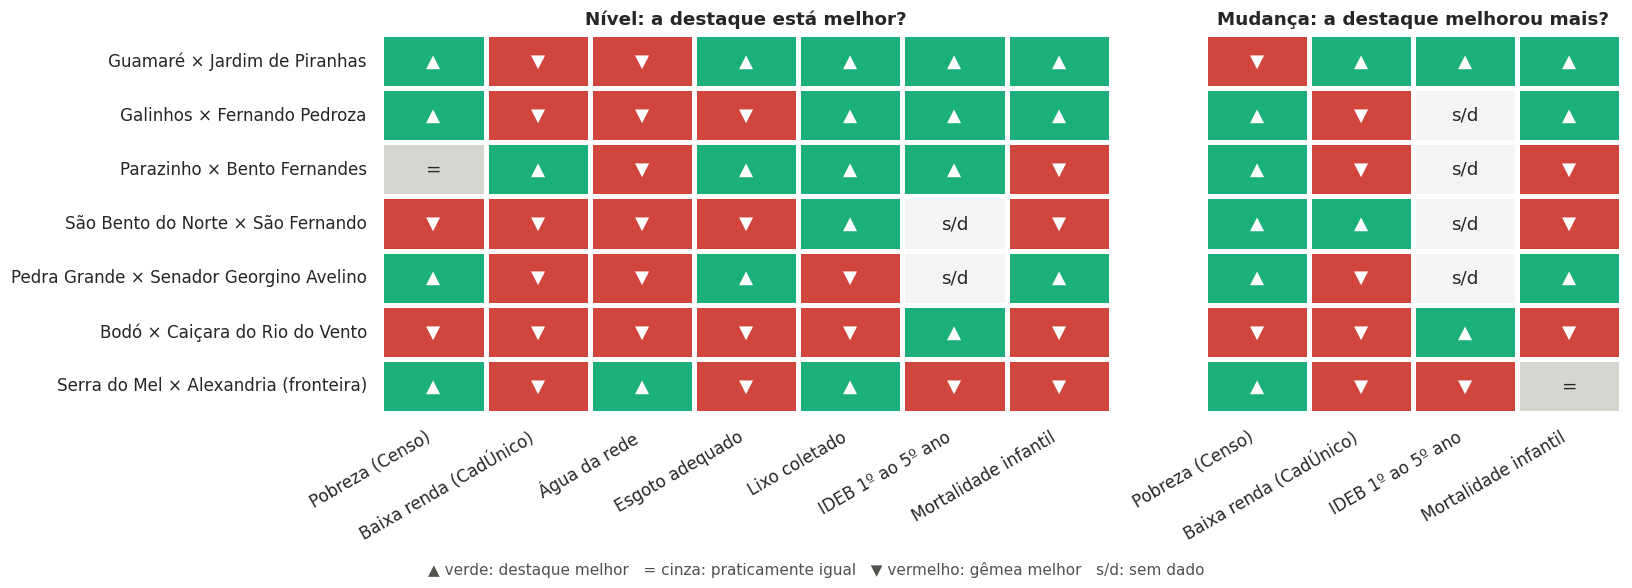

,nível,mudança
Destaque melhor,21,12
Igual,1,1
Gêmea melhor,25,11
Sem dado,2,4


In [11]:
def comparar(a, b, maior_melhor, tol):
    if pd.isna(a) or pd.isna(b):
        return np.nan
    dif = (a - b) if maior_melhor else (b - a)
    return 0 if abs(dif) < tol else (1 if dif > 0 else -1)

placar = {}
for tipo_cmp in ['nível', 'mudança']:
    usados = [i for i in INDICADORES if tipo_cmp == 'nível' or i[2]]
    m = pd.DataFrame(index=[ROTULO_PAR[d] for d, _ in PARES], columns=[n for n, *_ in usados], dtype=float)
    for d, g in PARES:
        for nome, nivel, mud, maior_melhor, tol in usados:
            col = nivel if tipo_cmp == 'nível' else mud
            m.loc[ROTULO_PAR[d], nome] = comparar(info.loc[d, col], info.loc[g, col],
                                                  True if tipo_cmp == 'mudança' else maior_melhor, tol)
    placar[tipo_cmp] = m

cmap = ListedColormap([VERMELHO, CINZA_CLARO, VERDE, '#f4f4f2'])
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True, gridspec_kw={'width_ratios': [7, 4]})
for ax, (tipo_cmp, m) in zip(axes, placar.items()):
    sns.heatmap(m.fillna(2).astype(float), cmap=cmap, vmin=-1.5, vmax=2.5, cbar=False, linewidths=2, linecolor='white',
                ax=ax, annot=m.replace({1: '▲', 0: '=', -1: '▼'}).fillna('s/d'), fmt='', annot_kws={'fontsize': 12})
    ax.set_title(f'{tipo_cmp.capitalize()}: a destaque está melhor?' if tipo_cmp == 'nível'
                 else 'Mudança: a destaque melhorou mais?', fontsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
    ax.set_ylabel('')
fig.text(0.5, -0.02, '▲ verde: destaque melhor   = cinza: praticamente igual   ▼ vermelho: gêmea melhor   s/d: sem dado',
         ha='center', fontsize=10, color=TEXTO_2)
plt.tight_layout()
plt.show()

contagem = pd.DataFrame({tipo_cmp: {'Destaque melhor': int((m == 1).sum().sum()), 'Igual': int((m == 0).sum().sum()),
                                    'Gêmea melhor': int((m == -1).sum().sum()), 'Sem dado': int(m.isna().sum().sum())}
                         for tipo_cmp, m in placar.items()})
contagem

In [12]:
por_indicador = pd.DataFrame({
    f'{tipo_cmp}: destaque melhor': (m == 1).sum() for tipo_cmp, m in placar.items()}).join(
    pd.DataFrame({f'{tipo_cmp}: gêmea melhor': (m == -1).sum() for tipo_cmp, m in placar.items()}))
por_indicador = (por_indicador.reindex([n for n, *_ in INDICADORES])
                 [['nível: destaque melhor', 'nível: gêmea melhor', 'mudança: destaque melhor', 'mudança: gêmea melhor']]
                 .apply(lambda col: col.map(lambda v: '–' if pd.isna(v) else str(int(v)))))
print('Número de pares (de 7) em que cada cidade está melhor. "–": mudança não comparada (saneamento).')
por_indicador

Número de pares (de 7) em que cada cidade está melhor. "–": mudança não comparada (saneamento).


,nível: destaque melhor,nível: gêmea melhor,mudança: destaque melhor,mudança: gêmea melhor
Pobreza (Censo),4,2,5,2
Baixa renda (CadÚnico),1,6,2,5
Água da rede,1,6,–,–
Esgoto adequado,3,4,–,–
Lixo coletado,5,2,–,–
IDEB 1º ao 5º ano,4,1,2,1
Mortalidade infantil,3,4,3,3


### 4.2 Educação: a trajetória do IDEB em cada par

IDEB da rede municipal (1º ao 5º ano) em 2017, 2019, 2021 e 2023. 2021 foi afetado pela pandemia em todo o país.

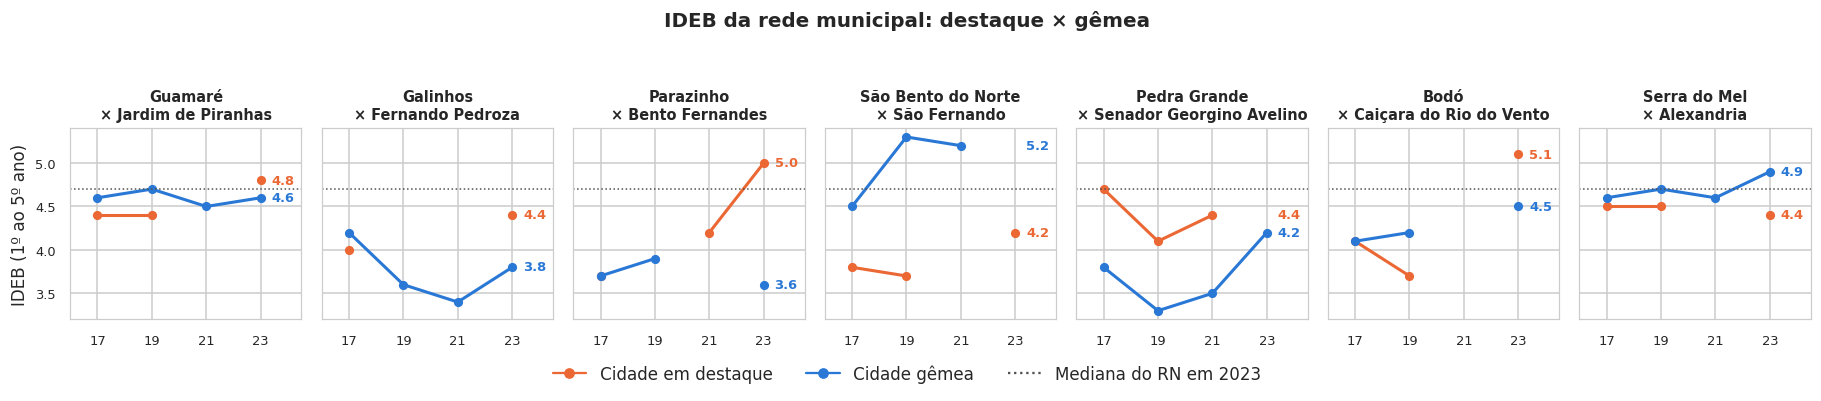

In [13]:
fig, axes = plt.subplots(1, len(PARES), figsize=(2.4 * len(PARES), 3.6), sharey=True)
anos_ideb = [2017, 2019, 2021, 2023]
for ax, (d, g) in zip(axes, PARES):
    for nome, cor in [(d, LARANJA), (g, AZUL)]:
        valores = [info.loc[nome, f'ai_{a}'] for a in anos_ideb]
        ax.plot(anos_ideb, valores, color=cor, marker='o', linewidth=2, markersize=5)
        ultimo = next((v for v in valores[::-1] if pd.notna(v)), None)
        if ultimo is not None:
            ax.text(2023.4, ultimo, f'{ultimo:.1f}', color=cor, fontsize=8.5, va='center', fontweight='bold')
    ax.axhline(ind['ai_2023'].median(), color=TEXTO_2, linestyle=':', linewidth=1)
    ax.set_title(f'{d}\n× {g}', fontsize=9.5)
    ax.set_xticks(anos_ideb)
    ax.set_xticklabels(['17', '19', '21', '23'])
    ax.set_xlim(2016, 2024.5)
    ax.tick_params(labelsize=8.5)
axes[0].set_ylabel('IDEB (1º ao 5º ano)')
fig.legend([plt.Line2D([], [], color=LARANJA, marker='o'), plt.Line2D([], [], color=AZUL, marker='o'),
            plt.Line2D([], [], color=TEXTO_2, linestyle=':')],
           ['Cidade em destaque', 'Cidade gêmea', 'Mediana do RN em 2023'], loc='lower center', ncol=3,
           frameon=False, bbox_to_anchor=(0.5, 0))
fig.suptitle('IDEB da rede municipal: destaque × gêmea', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.08, 1, 0.93))
plt.show()

### 4.3 Pobreza (Censo 2010 → 2022) e saneamento (Censo 2022)

À esquerda, cada seta vai da pobreza de 2010 à de 2022 (seta para a esquerda = a pobreza caiu). À direita, o saneamento
em 2022. Destaque em laranja, gêmea em azul.

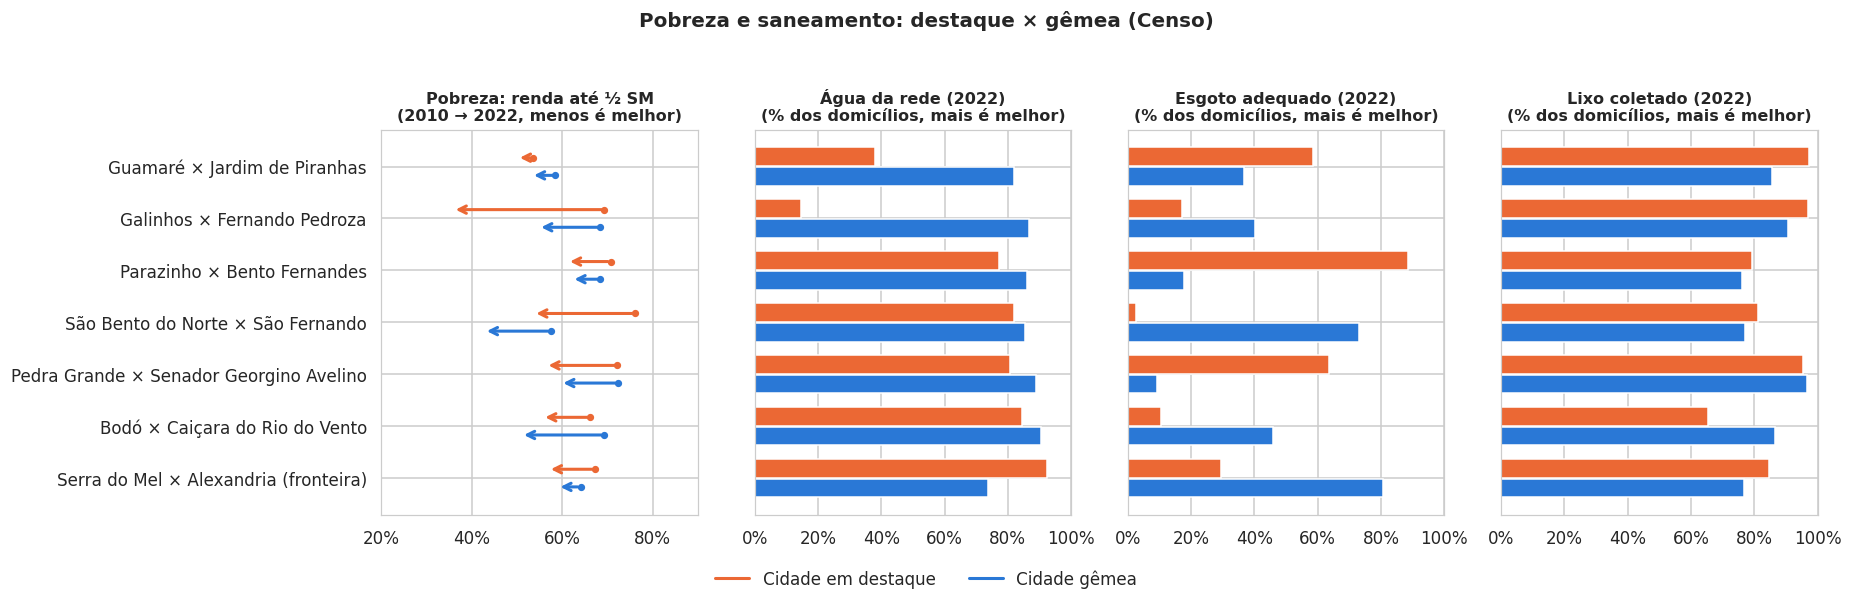

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 5.5), sharey=True)
y = np.arange(len(PARES))[::-1]
ax = axes[0]
for yi, (d, g) in zip(y, PARES):
    for nome, cor, desloc in [(d, LARANJA, 0.17), (g, AZUL, -0.17)]:
        a, b = info.loc[nome, 'pobre10'], info.loc[nome, 'pct_ate_meio_sm_censo']
        ax.annotate('', xy=(b, yi + desloc), xytext=(a, yi + desloc),
                    arrowprops=dict(arrowstyle='->', color=cor, linewidth=2))
        ax.scatter([a], [yi + desloc], color=cor, s=14)
ax.set_title('Pobreza: renda até ½ SM\n(2010 → 2022, menos é melhor)', fontsize=10.5)
ax.set_xlim(20, 90)
for ax, (titulo, col) in zip(axes[1:], [('Água da rede (2022)', 'agua22'), ('Esgoto adequado (2022)', 'esg22'),
                                        ('Lixo coletado (2022)', 'lixo22')]):
    for yi, (d, g) in zip(y, PARES):
        ax.barh(yi + 0.19, info.loc[d, col], height=0.36, color=LARANJA)
        ax.barh(yi - 0.19, info.loc[g, col], height=0.36, color=AZUL)
    ax.set_title(f'{titulo}\n(% dos domicílios, mais é melhor)', fontsize=10.5)
    ax.set_xlim(0, 100)
for ax in axes:
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
axes[0].set_yticks(y)
axes[0].set_yticklabels([ROTULO_PAR[d] for d, _ in PARES])
fig.legend([plt.Line2D([], [], color=LARANJA, linewidth=2), plt.Line2D([], [], color=AZUL, linewidth=2)],
           ['Cidade em destaque', 'Cidade gêmea'], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0))
fig.suptitle('Pobreza e saneamento: destaque × gêmea (Censo)', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.06, 1, 0.95))
plt.show()

### 4.4 Baixa renda no CadÚnico, ano a ano

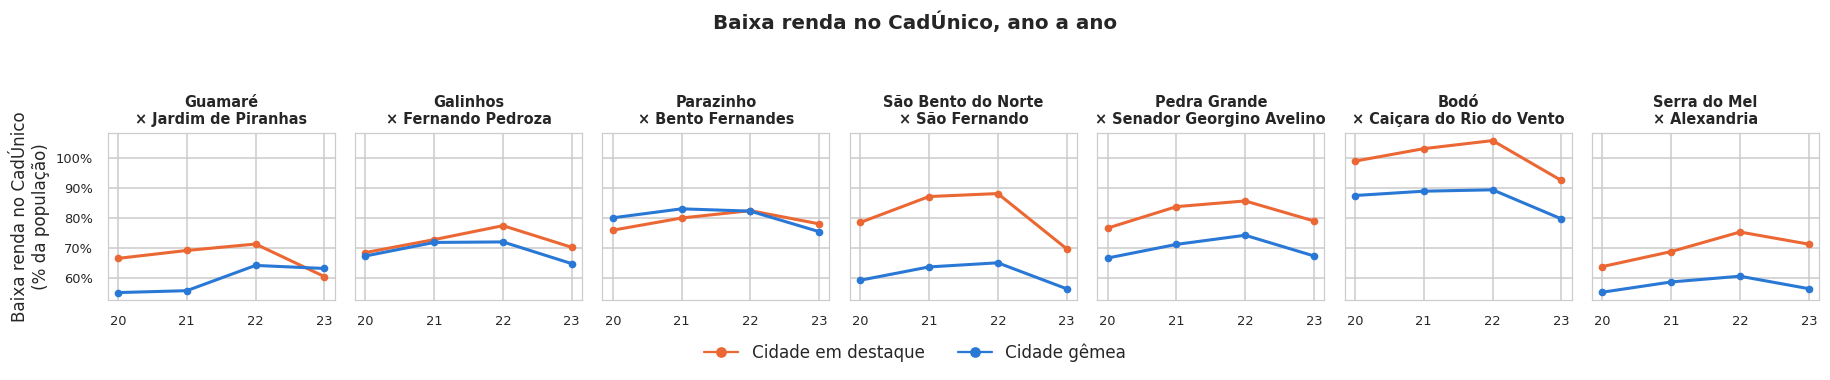

In [15]:
fig, axes = plt.subplots(1, len(PARES), figsize=(2.4 * len(PARES), 3.4), sharey=True)
for ax, (d, g) in zip(axes, PARES):
    for nome, cor in [(d, LARANJA), (g, AZUL)]:
        cod = info.loc[nome, 'cod_ibge']
        ax.plot(ANOS, cad.loc[cod, ANOS], color=cor, marker='o', linewidth=2, markersize=4)
    ax.set_title(f'{d}\n× {g}', fontsize=9.5)
    ax.set_xticks(ANOS)
    ax.set_xticklabels(['20', '21', '22', '23'])
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.tick_params(labelsize=8.5)
axes[0].set_ylabel('Baixa renda no CadÚnico\n(% da população)')
fig.legend([plt.Line2D([], [], color=LARANJA, marker='o'), plt.Line2D([], [], color=AZUL, marker='o')],
           ['Cidade em destaque', 'Cidade gêmea'], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, 0))
fig.suptitle('Baixa renda no CadÚnico, ano a ano', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0.08, 1, 0.92))
plt.show()

## 5. Conferência com os 167 municípios

Os pares são poucos (7). Para ver se o padrão vale para o RN inteiro, calculamos a **correlação de Spearman** entre o
dinheiro recebido por habitante (notebook 04) e cada indicador, nos 167 municípios. Ela vai de −1 a 1 e compara as
posições: positiva quer dizer que quem recebe mais tende a ter valor maior no indicador.

Como o tamanho do município influencia os dois lados (cidades pequenas recebem mais por habitante e costumam ter
indicadores diferentes), também mostramos a **correlação parcial**, que desconta o efeito da população.

Para facilitar a leitura, os sinais foram ajustados: **positivo = quem recebe mais está melhor** naquele indicador.

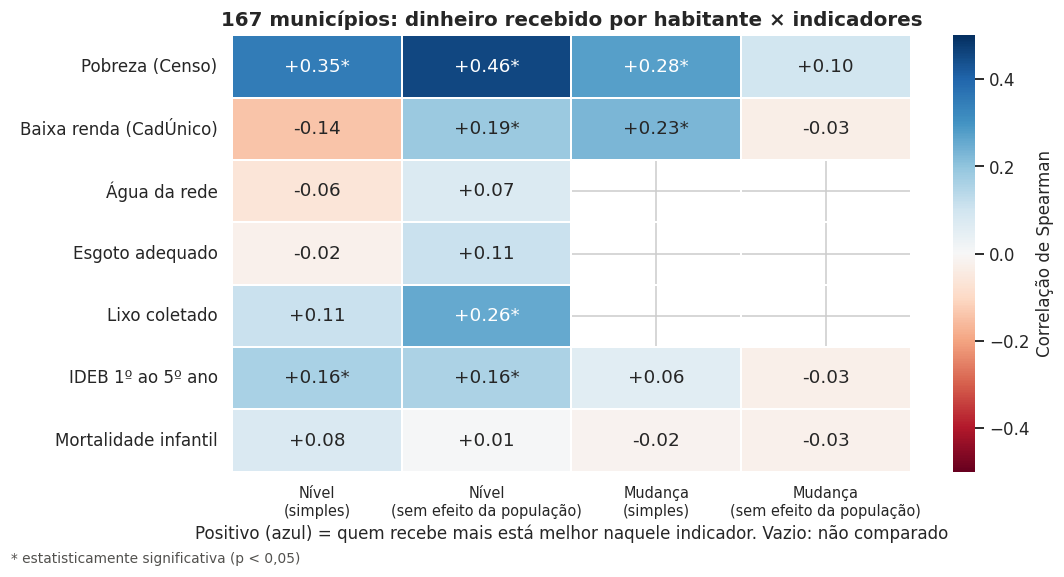

In [16]:
def correlacao_parcial(dados, x, y, controle):
    r = dados[[x, y, controle]].rank()
    res_x = r[x] - np.poly1d(np.polyfit(r[controle], r[x], 1))(r[controle])
    res_y = r[y] - np.poly1d(np.polyfit(r[controle], r[y], 1))(r[controle])
    return stats.pearsonr(res_x, res_y)

linhas_corr = []
for nome, nivel, mud, maior_melhor, _ in INDICADORES:
    for tipo_cmp, col, sinal in [('Nível', nivel, 1 if maior_melhor else -1), ('Mudança', mud, 1)]:
        if col is None:
            continue
        dados = ind[['total_pc_ano', col, 'populacao']].dropna()
        rho, p = stats.spearmanr(dados['total_pc_ano'], dados[col])
        rp, pp = correlacao_parcial(dados, 'total_pc_ano', col, 'populacao')
        linhas_corr.append({'Indicador': nome, 'Tipo': tipo_cmp, 'Simples': sinal * rho, 'p simples': p,
                            'Sem efeito da população': sinal * rp, 'p parcial': pp, 'Municípios': len(dados)})
corr = pd.DataFrame(linhas_corr)

mapa = corr.pivot_table(index='Indicador', columns='Tipo', values=['Simples', 'Sem efeito da população'])
mapa.columns = [f'{t}\n({c.lower()})' for c, t in mapa.columns]
ORDEM_COLS = ['Nível\n(simples)', 'Nível\n(sem efeito da população)', 'Mudança\n(simples)',
              'Mudança\n(sem efeito da população)']
mapa = mapa.loc[[n for n, *_ in INDICADORES], ORDEM_COLS]
p_mapa = corr.pivot_table(index='Indicador', columns='Tipo', values=['p simples', 'p parcial'])
anotacao = mapa.copy().astype(str)
for coluna in mapa.columns:
    tipo_cmp = coluna.split('\n')[0]
    pcol = 'p parcial' if 'população' in coluna else 'p simples'
    for indicador in mapa.index:
        v = mapa.loc[indicador, coluna]
        if pd.isna(v):
            anotacao.loc[indicador, coluna] = ''
            continue
        p = p_mapa.loc[indicador, (pcol, tipo_cmp)]
        anotacao.loc[indicador, coluna] = f'{v:+.2f}' + ('*' if p < 0.05 else '')

fig, ax = plt.subplots(figsize=(10, 5.2))
sns.heatmap(mapa, annot=anotacao, fmt='', cmap='RdBu', center=0, vmin=-0.5, vmax=0.5,
            linewidths=1, linecolor='white', cbar_kws={'label': 'Correlação de Spearman'}, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=9.5)
ax.set_xlabel('Positivo (azul) = quem recebe mais está melhor naquele indicador. Vazio: não comparado')
ax.set_ylabel('')
ax.set_title('167 municípios: dinheiro recebido por habitante × indicadores')
fig.text(0.01, 0.0, '* estatisticamente significativa (p < 0,05)', fontsize=9, color=TEXTO_2)
plt.tight_layout()
plt.show()

### 5.1 Dinheiro × IDEB nos 167 municípios

Cada ponto é um município. As cidades em destaque e as gêmeas estão em cor. A linha tracejada horizontal é a mediana
do IDEB no RN.

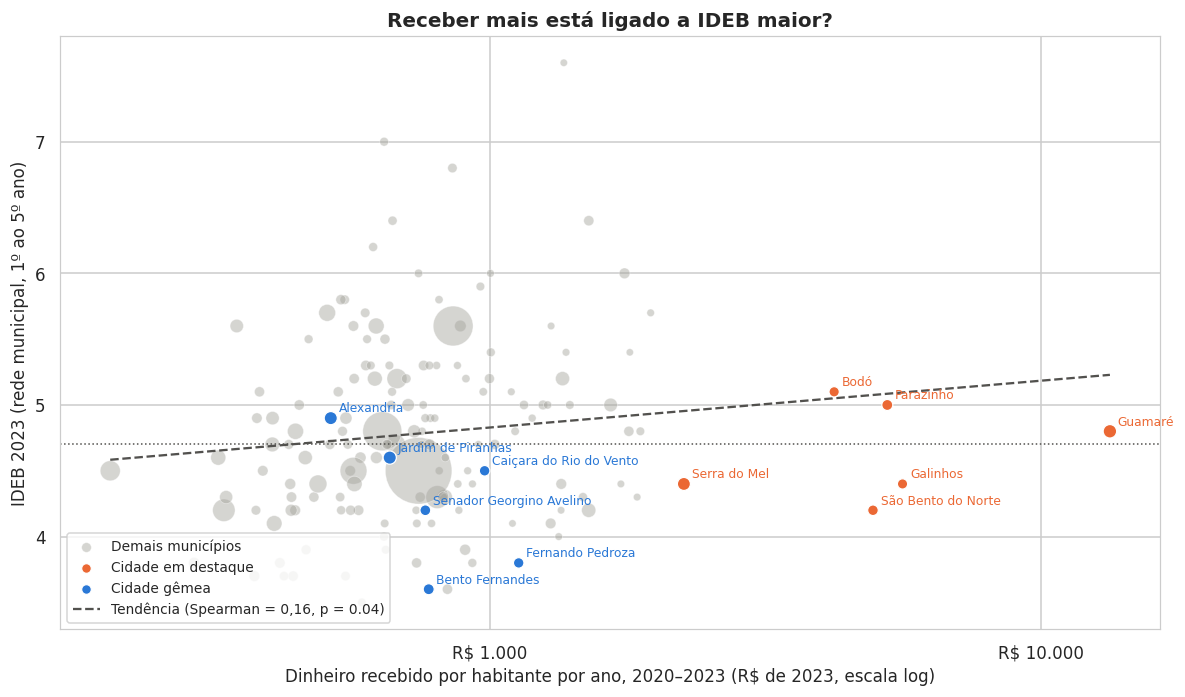

In [17]:
dados = ind.dropna(subset=['ai_2023'])
fig, ax = plt.subplots(figsize=(11, 6.5))
demais = dados[~dados['municipio'].isin(CIDADES)]
ax.scatter(demais['total_pc_ano'], demais['ai_2023'], s=demais['populacao'] / 400 + 18, color=CINZA, alpha=0.45,
           edgecolor='white', linewidth=0.5, label='Demais municípios')
for grupo, cor in [(DESTAQUES, LARANJA), (GEMEAS, AZUL)]:
    sub = dados[dados['municipio'].isin(grupo)]
    ax.scatter(sub['total_pc_ano'], sub['ai_2023'], s=sub['populacao'] / 400 + 40, color=cor, edgecolor='white',
               linewidth=0.8, zorder=3, label='Cidade em destaque' if cor == LARANJA else 'Cidade gêmea')
    for _, linha in sub.iterrows():
        ax.annotate(linha['municipio'], (linha['total_pc_ano'], linha['ai_2023']), xytext=(5, 4),
                    textcoords='offset points', fontsize=8, color=cor)
x_log = np.log10(dados['total_pc_ano'])
ajuste = stats.linregress(x_log, dados['ai_2023'])
xs = np.linspace(x_log.min(), x_log.max(), 50)
rho, p = stats.spearmanr(dados['total_pc_ano'], dados['ai_2023'])
ax.plot(10 ** xs, ajuste.intercept + ajuste.slope * xs, color=TEXTO_2, linestyle='--', linewidth=1.5,
        label=f'Tendência (Spearman = {virgula(rho, 2)}, p = {p:.2f})')
ax.axhline(dados['ai_2023'].median(), color=TEXTO_2, linestyle=':', linewidth=1)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'R$ {v:,.0f}'.replace(',', '.')))
ax.set_xlabel('Dinheiro recebido por habitante por ano, 2020–2023 (R$ de 2023, escala log)')
ax.set_ylabel('IDEB 2023 (rede municipal, 1º ao 5º ano)')
ax.set_title('Receber mais está ligado a IDEB maior?')
legenda = ax.legend(loc='lower left', fontsize=9)
for marcador in legenda.legend_handles[:3]:
    marcador.set_sizes([40])
plt.tight_layout()
plt.show()

## 6. Síntese

| Pergunta | Resposta | Onde ver |
|---|---|---|
| A cidade que recebe mais depende menos de transferências? | **Pouco.** 89% da receita ainda vem de transferências (95% nas gêmeas); a diferença é que depende do Estado (ICMS), e não do FPM | Seção 2 |
| Para onde vai o dinheiro a mais? | **Administração e Câmara** (mediana de R\$ 40 de cada R\$ 100), saúde (R\$ 24) e educação (R\$ 20); quase nada para obras e saneamento. Vai para custeio e pessoal, não para investimento | Seção 3 |
| O dinheiro a mais virou melhoria? | **Não de forma clara nos pares** (placar de 21 × 25). Nos 167 municípios, quem recebe mais tem menos pobreza e IDEB um pouco maior, mas sem relação com saneamento e saúde | Seções 4 e 5 |

**Limites (importante dizer na apresentação):**

- **São só 7 pares.** O placar mostra uma tendência, e não uma prova estatística.
- **Associação não é causa.** A gêmea é parecida em tamanho e região, mas não em tudo: gestão, história e economia
  também pesam. A pobreza menor nas cidades que recebem mais pode vir da própria atividade econômica (usinas,
  petróleo), e não do gasto da prefeitura.
- **Galinhos e Bodó** têm gêmeas cerca de 40% maiores (notebook 05).
- **Saneamento** foi comparado só no nível de 2022, porque o Censo mudou as definições entre 2010 e 2022.
- **Mortalidade infantil** em cidades pequenas oscila muito: poucas mortes mudam a taxa.
- **"Administração"** no SICONFI é uma área ampla: inclui secretarias de administração e finanças, mas também despesas
  gerais que a prefeitura não atribui a outra área.